In [1]:
import pandas as pd
from pipeline import IndicatorSpec, build_feature_df
from data import fetch_binance_klines
from simulation.rules import Rule, RuleGroup, ALL, ANY
from simulation.rule_features import add_last_n_compare, add_cross_compare
from simulation.simulator import Strategy, SimConfig, run_simulation, align_timeframes
from plot_simulation import plot_simulation
from plotter import plot_interactive, PlotConfig, IndicatorSpec
from mtf_plot import make_plot_indicators, assert_plot_columns_exist
from features.ema_spreads import EmaSpreadSpec, add_ema_spread_features
from features.cross_through import CrossThroughSpec, add_cross_through_features
from simulation.rules import Ctx
from analytics import (
    trades_to_frame,
    plot_balance_by_trade,
    plot_trade_pnl_bars,
    trade_summary_table
)
from plot_toggles import (
    PlotToggle,
    make_plot_indicators_from_toggles,
    assert_plot_columns_exist,
)

from ema_diagnostic_plots import (
    ema_pair_spread_panel,
    ema_group_spread_panel,
    ema_cut_through_panel,
)

In [2]:
symbol = "BTCUSDT"
market = "spot"
tz = "Asia/Karachi"

# Start earlier for EMA warmup.
fetch_start = "2026-01-01"
sim_start = "2026-05-06"
end = None

In [3]:
RSI_DIV_CFG = {
    "length": 14,
    "pivot_lookback": 5,
    "min_rsi_delta": 2,

    # divergence filtering
    "os_level": 30,
    "ob_level": 70,
    "zone_mode": "cross",

    # panel styling
    "major_levels": [30, 70],
    "minor_levels": [20, 80],
    "show_zone_shading": True,

    # divergence labels
    "show_div_labels": True,
    "max_div_labels": 6,
    "label_font_size": 10,
    "label_xshift": 10,
    "label_yshift": 14,

    # main chart markers
    "mark_price": True,
    "price_marker_size": 18,
    "marker_offset_mult": 1.35,
}

In [4]:
### 1 Minute Indicators ###
EMA50_1m = "1m__ema__EMA_50"
EMA100_1m = "1m__ema__EMA_100"
EMA150_1m = "1m__ema__EMA_150"
EMA200_1m = "1m__ema__EMA_200"
MACD_1M = "1m__macd_8_21_5__MACD"
MACD_SIGNAL_1M = "1m__macd_8_21_5__SIGNAL"
MACD_HIST_1M = "1m__macd_8_21_5__HIST"
BULL_DIV_1m = "1m__rsi14__BULL_DIV"
BEAR_DIV_1m = "1m__rsi14__BEAR_DIV"
BULL_START_RSI_1m = "1m__rsi14__BULL_START_RSI"
BEAR_START_RSI_1m = "1m__rsi14__BEAR_START_RSI"


### 5 Minute Indicators ###
EMA50_5m = "5m__ema__EMA_50"
EMA75_5m = "5m__ema__EMA_75"
EMA100_5m = "5m__ema__EMA_100"
EMA125_5m = "5m__ema__EMA_125"
EMA150_5m = "5m__ema__EMA_150"
EMA175_5m = "5m__ema__EMA_175"
EMA200_5m = "5m__ema__EMA_200"
MACD_5M = "5m__macd_8_21_5__MACD"
MACD_SIGNAL_5M = "5m__macd_8_21_5__SIGNAL"
MACD_HIST_5M = "5m__macd_8_21_5__HIST"
BULL_DIV_5m = "5m__rsi14__BULL_DIV"
BEAR_DIV_5m = "5m__rsi14__BEAR_DIV"
BULL_START_RSI_5m = "5m__rsi14__BULL_START_RSI"
BEAR_START_RSI_5m = "5m__rsi14__BEAR_START_RSI"


### 15 Minute Indicators ###
EMA50_15m = "15m__ema__EMA_50"
EMA75_15m = "15m__ema__EMA_75"
EMA100_15m = "15m__ema__EMA_100"
EMA125_15m = "15m__ema__EMA_125"
EMA150_15m = "15m__ema__EMA_150"
EMA175_15m = "15m__ema__EMA_175"
EMA200_15m = "15m__ema__EMA_200"
MACD_15M = "15m__macd_8_21_5__MACD"
MACD_SIGNAL_15M = "15m__macd_8_21_5__SIGNAL"
MACD_HIST_15M = "15m__macd_8_21_5__HIST"
BULL_DIV_15m = "15m__rsi14__BULL_DIV"
BEAR_DIV_15m = "15m__rsi14__BEAR_DIV"
BULL_START_RSI_15m = "15m__rsi14__BULL_START_RSI"
BEAR_START_RSI_15m = "15m__rsi14__BEAR_START_RSI"


LONG_EMA_FILTERS = [
    EMA50_1m,
    EMA100_1m,
    EMA150_1m,
    EMA200_1m,
    EMA100_5m,
    EMA200_5m,
    EMA100_15m,
    EMA200_15m
]

In [5]:
ind_1m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 100, 150, 200, 250],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("rsi_divergence", tag="rsi14", config=RSI_DIV_CFG),
]


ind_5m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("rsi_divergence", tag="rsi14", config=RSI_DIV_CFG),
]


ind_15m = [
    IndicatorSpec("moving_average", tag="ema", config={
        "type": "ema",
        "periods": [50, 75, 100, 125, 150, 175, 200],
        "source": "close",
    }),

    IndicatorSpec("macd", tag="macd_8_21_5", config={
        "fast": 8,
        "slow": 21,
        "signal": 5,
    }),

    IndicatorSpec("rsi_divergence", tag="rsi14", config=RSI_DIV_CFG),
]

####### EMA spread features

EMA50_1m = "1m__ema__EMA_50"
EMA100_1m = "1m__ema__EMA_100"

EMA100_5m = "5m__ema__EMA_100"
EMA100_15m = "15m__ema__EMA_100"

spread_specs = [
    EmaSpreadSpec(
        name="spread_1m_ema50_vs_1m_ema100",
        left=EMA50_1m,
        right=EMA100_1m,
    ),
    EmaSpreadSpec(
        name="spread_1m_ema50_vs_5m_ema100",
        left=EMA50_1m,
        right=EMA100_5m,
    ),
    EmaSpreadSpec(
        name="spread_1m_ema50_vs_15m_ema100",
        left=EMA50_1m,
        right=EMA100_15m,
    ),
]

####### EMA Diagnostics
LONG_EMA_FILTERS = [
    EMA50_1m,
    EMA100_1m,
    EMA150_1m,
    EMA100_5m,
    EMA200_5m,
    EMA100_15m,
    EMA200_15m
]

from features.ema_diagnostics import (
    EmaPairSpreadSpec,
    EmaGroupSpreadSpec,
    EmaCutThroughSpec,
    add_ema_diagnostics,
)

pair_specs = [
    EmaPairSpreadSpec(
        name="spread_1m_ema50_vs_5m_ema100",
        left=EMA50_1m,
        right=EMA100_5m,
    ),
    EmaPairSpreadSpec(
        name="spread_1m_ema50_vs_15m_ema100",
        left=EMA50_1m,
        right=EMA100_15m,
    ),
]

group_specs = [
    EmaGroupSpreadSpec(
        name="long_ema_filter_spread",
        cols=LONG_EMA_FILTERS,
    )
]

cut_specs = [
    EmaCutThroughSpec(
        name="cut_1m_ema50_through_long_filters",
        leader=EMA50_1m,
        others=[
            EMA100_1m,
            EMA150_1m,
            EMA100_5m,
            EMA200_5m,
            EMA100_15m,
            EMA200_15m,
        ],
        lookbacks=(3, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50),
    )
]

In [6]:
# 1m base data
df1 = fetch_binance_klines(
    symbol=symbol,
    interval="1m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df1_feat, _, _ = build_feature_df(
    raw_df=df1,
    tz=tz,
    ma_windows=[],
    indicators=ind_1m,
)


# 5m filter data
df5 = fetch_binance_klines(
    symbol=symbol,
    interval="5m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df5_feat, _, _ = build_feature_df(
    raw_df=df5,
    tz=tz,
    ma_windows=[],
    indicators=ind_5m,
)


# 15m filter data
df15 = fetch_binance_klines(
    symbol=symbol,
    interval="15m",
    start=fetch_start,
    end=end,
    market=market,
    cache=True,
    cache_dir="data",
)

df15_feat, _, _ = build_feature_df(
    raw_df=df15,
    tz=tz,
    ma_windows=[],
    indicators=ind_15m,
)

merged = align_timeframes(
    base_df=df1_feat,
    other_dfs={
        "5m": df5_feat,
        "15m": df15_feat,
    },
    base_label="1m",
)


[17:23:52] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=1m, start=2026-01-01 00:00:00+00:00, end=LATEST
[17:23:52] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[17:23:52] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_1m.parquet
[17:23:52] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\.partials\binance_spot_BTCUSDT_1m
[17:23:52] INFO | 05. Cache: HIT | rows=198,254 (main_rows=198,254, partial_files=0) | range=2026-01-01 00:00:00+00:00 -> 2026-05-18 16:13:00+00:00
[17:23:52] INFO | 06. Fetch plan 1/1: 2026-05-18 16:14:00+00:00 -> LATEST
[17:23:52] INFO | 07. Starting fetch range 1/1.


BTCUSDT 1m: 0page [00:00, ?page/s]

[17:23:55] INFO | 08. Completed fetch range 1/1 | rows=1,210 | total_rows_fetched=1,210 | requests=2 | retries=0 | elapsed=3.1s
[17:23:55] INFO | 09. Cache consolidated and saved (parquet) | rows=199,464 | range=2026-01-01 00:00:00+00:00 -> 2026-05-19 12:23:00+00:00 | cleared_partial_files=2
[17:23:55] INFO | 10. Fetch summary | new_rows=1,210 | successful_pages=2 | requests=2 | retries=0 | partial_saves=2 | elapsed=3.5s
[17:23:55] INFO | 11. Returning slice | rows=199,464 | range=2026-01-01 00:00:00+00:00 -> 2026-05-19 12:23:00+00:00
[17:24:19] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=5m, start=2026-01-01 00:00:00+00:00, end=LATEST
[17:24:19] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[17:24:19] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_5m.parquet
[17:24:19] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Bin

BTCUSDT 5m: 0page [00:00, ?page/s]

[17:24:19] INFO | 08. Completed fetch range 1/1 | rows=242 | total_rows_fetched=242 | requests=1 | retries=0 | elapsed=0.9s
[17:24:20] INFO | 09. Cache consolidated and saved (parquet) | rows=145,013 | range=2025-01-01 00:00:00+00:00 -> 2026-05-19 12:20:00+00:00 | cleared_partial_files=1
[17:24:20] INFO | 10. Fetch summary | new_rows=242 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=1.2s
[17:24:20] INFO | 11. Returning slice | rows=39,893 | range=2026-01-01 00:00:00+00:00 -> 2026-05-19 12:20:00+00:00
[17:24:23] INFO | 01. Parameters: market=spot, symbol=BTCUSDT, interval=15m, start=2026-01-01 00:00:00+00:00, end=LATEST
[17:24:23] INFO | 02. Cache directory: C:\Users\Talal Zahid\Desktop\Talal\Binance\data (cwd=C:\Users\Talal Zahid\Desktop\Talal\Binance)
[17:24:23] INFO | 03. Main cache file: C:\Users\Talal Zahid\Desktop\Talal\Binance\data\binance_spot_BTCUSDT_15m.parquet
[17:24:23] INFO | 04. Partial checkpoint dir: C:\Users\Talal Zahid\Desktop\Talal\Binance\

BTCUSDT 15m: 0page [00:00, ?page/s]

[17:24:24] INFO | 08. Completed fetch range 1/1 | rows=81 | total_rows_fetched=81 | requests=1 | retries=0 | elapsed=0.7s
[17:24:24] INFO | 09. Cache consolidated and saved (parquet) | rows=13,298 | range=2026-01-01 00:00:00+00:00 -> 2026-05-19 12:15:00+00:00 | cleared_partial_files=1
[17:24:24] INFO | 10. Fetch summary | new_rows=81 | successful_pages=1 | requests=1 | retries=0 | partial_saves=1 | elapsed=0.8s
[17:24:24] INFO | 11. Returning slice | rows=13,298 | range=2026-01-01 00:00:00+00:00 -> 2026-05-19 12:15:00+00:00


In [22]:
####### EMA spread features (Merged)
merged = add_ema_spread_features(
    merged,
    specs=spread_specs,
    dynamic_windows=(250, 500, 750, 1000),
    dynamic_quantiles=(0.3, 0.4, 0.45, 0.50, 0.60, 0.65),
)

merged = add_ema_diagnostics(
    merged,
    pair_specs=pair_specs,
    group_specs=group_specs,
    cut_specs=cut_specs,
    dynamic_windows=(250, 500, 750, 1000),
    dynamic_quantiles=(0.3, 0.4, 0.45, 0.50, 0.60, 0.65),
)

# for col in merged.columns:
#     print(col)

In [34]:
N_CONFIRM = 1             # number of consecutive confirmation candles required
MAX_WAIT_AFTER_CROSS = 30   # how many candles after the cross we are willing to wait
MACD_THRESHOLD_1M = 10
MACD_THRESHOLD_5M = 10
MACD_THRESHOLD_15M = 50 

MIN_MACD_DIFF_1M = 5
MIN_MACD_DIFF_5M = 5
MIN_MACD_DIFF_15M = 5

DIV_LOOKBACK = 5

N_SPREAD_CONFIRM = 3
MIN_SPREAD_PCT = 0.1

MIN_EMAS_CROSSED = 4
CROSS_LOOKBACK = 40


########### CROSS UP MERGED


merged = add_cross_through_features(
    merged,
    specs=[
        CrossThroughSpec(
            name="ema50_1m_cut_up",
            leader=EMA50_1m,
            refs=LONG_EMA_FILTERS,
            direction="up",
            lookback=CROSS_LOOKBACK,
            include_current=True,
            require_current_side=True,
            add_debug_cols=False,
        ),
        
        # This detects zig-zag / failed continuation.
        # require_current_side=False means: count any down-cross event in the lookback,
        # even if EMA50 later moved back above.
        CrossThroughSpec(
            name="ema50_1m_cut_down_any",
            leader=EMA50_1m,
            refs=LONG_EMA_FILTERS,
            direction="down",
            lookback=CROSS_LOOKBACK,
            include_current=True,
            require_current_side=False,
            add_debug_cols=False,
        ),
    ],
)



###################### long rules #########################
open_rules_long = ALL(
    Rule(
        "Current close above all EMA filters",
        lambda c: c.close_above_all(LONG_EMA_FILTERS)
    ),

    Rule(
        f"Last {N_CONFIRM} closes above all EMA filters",
        lambda c: c.last_n_closes_above_all(LONG_EMA_FILTERS, n=N_CONFIRM)
    ),

    Rule(
        f"Last {N_CONFIRM} candles green",
        lambda c: c.consecutive_green(n=N_CONFIRM)
    ),

    # Optional but recommended: 1m EMA ribbon should be bullish
    Rule(
        "1m EMA ribbon bullish: EMA50 > EMA100 > EMA150",
        lambda c: (
            c.gt(EMA50_1m, EMA100_1m)
            and c.gt(EMA100_1m, EMA150_1m)
        )
    ),

        # Optional but recommended: 1m EMA ribbon should be bullish
    Rule(
        "1m EMA ribbon bullish: EMA50 > EMA100 > EMA150",
        lambda c: (
            c.gt(EMA50_5m, EMA100_5m)
            and c.gt(EMA100_5m, EMA150_5m)
        )
    ),

        # Optional but recommended: 1m EMA ribbon should be bullish
    Rule(
        "1m EMA ribbon bullish: EMA50 > EMA100 > EMA150",
        lambda c: (
            c.gt(EMA50_15m, EMA100_15m)
            and c.gt(EMA100_15m, EMA150_15m)
        )
    ),

    Rule(
        "1m MACD above threshold",
        lambda c: c.gt(MACD_1M, MACD_THRESHOLD_1M)
    ),
    
    Rule(
        "5m MACD above threshold",
        lambda c: c.gt(MACD_5M, MACD_THRESHOLD_5M)
    ),
    
    Rule(
        "15m MACD above threshold",
        lambda c: c.gt(MACD_15M, MACD_THRESHOLD_15M)
    ),

    Rule(
        "1m MACD - Signal above minimum",
        lambda c: c.gt(MACD_HIST_1M, MIN_MACD_DIFF_1M)
    ),
    
    Rule(
        "5m MACD - Signal above minimum",
        lambda c: c.gt(MACD_HIST_5M, MIN_MACD_DIFF_5M)
    ),

    Rule(
        "15m MACD - Signal above minimum",
        lambda c: c.gt(MACD_HIST_15M, MIN_MACD_DIFF_15M)
    ),

    # Rule(
    #     f"No bearish RSI divergence in last {DIV_LOOKBACK} candles",
    #     lambda c: not c.flag_recent(BEAR_DIV_1m, lookback=1200)
    # ),
    #     Rule(
    #     f"No bearish RSI divergence in last {DIV_LOOKBACK} candles",
    #     lambda c: not c.flag_recent(BEAR_DIV_15m, lookback=10)
    # ),
    #     Rule(
    #     f"No bearish RSI divergence in last {DIV_LOOKBACK} candles",
    #     lambda c: not c.flag_recent(BEAR_DIV_15m, lookback=10)
    # ),
)


ema_spread_filter_long_static = ALL(
    Rule(
        f"Last {N_CONFIRM} closes above all EMA filters",
        lambda c: c.last_n_closes_above_all(LONG_EMA_FILTERS, n=N_CONFIRM)
    ),
    Rule(
        f"1m EMA50 vs 5m EMA100 spread above dynamic threshold for {N_SPREAD_CONFIRM} candles",
        lambda c: c.last_all_compare(
            "spread_1m_ema50_vs_5m_ema100__pct",
            ">",
            "spread_1m_ema50_vs_5m_ema100__pct__q60_w500",
            n=N_SPREAD_CONFIRM,
        )
    ),
    
   Rule(
        "EMA basket spread above rolling q80",
        lambda c: c.gt(
            "long_ema_filter_spread__range_pct",
            "long_ema_filter_spread__range_pct_q50_w500",
        )
    ),

    # Rule(
    #     f"1m EMA50 crossed above at least {MIN_EMAS_CROSSED} EMAs in last {CROSS_LOOKBACK} candles",
    #     lambda c: c.crossed_up_through_at_least(
    #         leader=EMA50_1m,
    #         refs=LONG_EMA_FILTERS,
    #         min_crosses=MIN_EMAS_CROSSED,
    #         lookback=CROSS_LOOKBACK,
    #         include_current=True,
    #         require_current_side=True,
    #         unique=True,
    #     )
    # ),

    Rule(
        f"1m EMA50 crossed above at least {MIN_EMAS_CROSSED} EMAs in last {CROSS_LOOKBACK} candles",
        lambda c: c.gte("ema50_1m_cut_up__count", MIN_EMAS_CROSSED)
    ),
    Rule(
        f"No EMA50 downward cuts in last {30} candles",
        lambda c: c.lte("ema50_1m_cut_down_any__count", 0)
    ),
)

    
# )

#EMA75_15m = "15m__ema__EMA_75"

close_rules_long = ALL(
    Rule(
        "Close below EMA100",
        lambda c: c.lt("close", EMA100_15m)
    ),
)

###################### short rules #########################

# open_rules_short = ALL(
#     Rule(
#         f"Close crossed below EMA50 and later {N_CONFIRM} red confirmations",
#         lambda c: c.cross_down_with_later_confirm(
#             left="close",
#             right=EMA50,
#             max_bars_since_cross=MAX_WAIT_AFTER_CROSS,
#             confirm_bars=N_CONFIRM,
#             confirm_pattern="red",
#             require_same_side=True,
#             require_no_opposite_cross=True,
#         )
#     ),
# )


# close_rules_short = ALL(
#     Rule(
#         "Close above EMA50",
#         lambda c: c.gt("close", EMA50)
#     ),
# )

In [35]:
strategy = Strategy(
    open_rules_long=ema_spread_filter_long_static,
    close_rules_long=close_rules_long,

    # allow_short=True,
    # open_rules_short=open_rules_short,
    # close_rules_short=close_rules_short,
)

res = run_simulation(
    df=merged,
    strategy=strategy,
    cfg=SimConfig(
        initial_cash=10_000,
        max_open_trades=1,
        fee_bps=10,
        slippage_bps=1,
        # sim_start=sim_start,
        sim_start="2026-01-01",
        sim_end="2026-05-18",
        #sim_start="2026-05-10",
        #sim_end="2026-05-15",
        sim_tz=tz,
    ),
    time_col="t",
    price_col="close",
)

res.stats #, res.events.head(), res.equity_curve.tail()

[18:21:29] INFO | Simulation window applied | rows=198,420/199,464 | range=2026-01-01 05:00:00+05:00 -> 2026-05-18 23:59:00+05:00


Simulation:   0%|          | 0/198420 [00:00<?, ?bar/s]

[18:21:29] INFO | Simulation started | bars=198,420 | initial_cash=10,000.00 | cash_per_trade=10,000.00 | max_open_trades=1 | fee_bps=10 | slippage_bps=1
[18:21:38] INFO | Simulation finished | elapsed=11.14s | bars=198,420 | opened=23 | closed=23 | final_cash=10,330.01 | total_return=3.30% | max_dd=7.16%


{'initial_cash': 10000.0,
 'final_cash': 10330.005463103029,
 'total_pnl': 330.00546310302866,
 'total_return_pct': 3.3000546310302914,
 'num_trades': 23.0,
 'num_winners': 11.0,
 'num_losers': 12.0,
 'num_breakeven': 0.0,
 'win_rate_pct': 47.82608695652174,
 'loss_rate_pct': 52.17391304347826,
 'gross_profit': 1386.9408488151464,
 'gross_loss': 1056.9353857121177,
 'profit_factor': 1.3122286069367288,
 'avg_pnl': 14.348063613175158,
 'median_pnl': -6.068346849242911,
 'avg_winner': 126.08553171046786,
 'avg_loser': -88.07794880934314,
 'avg_loser_abs': 88.07794880934314,
 'largest_winner': 231.8854250382955,
 'largest_loser': -164.01662579950272,
 'payoff_ratio': 1.4315221166582497,
 'expectancy_per_trade': 14.348063613175158,
 'expectancy_pct_initial_cash': 0.14348063613175158,
 'avg_return_pct': 0.1434806361317516,
 'median_return_pct': -0.0606834684924291,
 'best_return_pct': 2.3188542503829552,
 'worst_return_pct': -1.6401662579950274,
 'avg_duration_min': 840.5652173913044,
 'med

In [36]:
ema_pair_panel = ema_pair_spread_panel(
    name="spread_1m_ema50_vs_5m_ema100",
    title="Spread: 1m EMA50 vs 5m EMA100 (%)",
    mode="pct",
    dynamic_threshold_cols=[
        "spread_1m_ema50_vs_5m_ema100__pct__q60_w500",
    ],
)

ema_group_panel = ema_group_spread_panel(
    name="long_ema_filter_spread",
    title="EMA Basket Spread / Compression",
    metrics=("range_pct", "std_pct", "mad_pct"),
    dynamic_threshold_cols=[
        "long_ema_filter_spread__range_pct_q50_w500",
    ],
)

ema_cut_panel = ema_cut_through_panel(
    name="cut_1m_ema50_through_long_filters",
    lookback=CROSS_LOOKBACK,
    title="1m EMA50 Cut-Through Speed",
)

In [37]:
trade_summary_table(res.trades, initial_cash=10_000, interval="1m")

,trade_no,trade_id,side,entry_time,exit_time,entry_price,exit_price,qty,pnl,return_pct,duration_min,candle_count,balance,open_reason,close_reason
1,1,1.0,long,2026-01-12 05:23:00+05:00,2026-01-12 05:51:00+05:00,91148.963985,90712.927800,0.109711,-67.789918,-0.478378,28.0,28.0,9932.210082,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
2,2,2.0,long,2026-01-27 21:37:00+05:00,2026-01-27 22:11:00+05:00,88578.326947,88091.199999,0.112894,-74.938927,-0.549939,34.0,34.0,9857.271156,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
3,3,3.0,long,2026-02-15 09:24:00+05:00,2026-02-15 17:50:00+05:00,70213.430641,69881.011200,0.142423,-67.296795,-0.473441,506.0,506.0,9789.974361,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
4,4,4.0,long,2026-02-25 06:24:00+05:00,2026-02-26 19:06:00+05:00,66048.594199,67693.230000,0.151404,228.754903,2.490039,2202.0,2202.0,10018.729264,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
5,5,5.0,long,2026-02-27 09:18:00+05:00,2026-02-27 11:27:00+05:00,68086.237943,67522.237101,0.146873,-102.753411,-0.828362,129.0,129.0,9915.975853,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
6,6,6.0,long,2026-03-02 19:53:00+05:00,2026-03-03 10:47:00+05:00,66956.695000,67982.221098,0.149350,133.009430,1.531626,894.0,894.0,10048.985283,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
7,7,7.0,long,2026-03-03 21:32:00+05:00,2026-03-03 21:43:00+05:00,68504.209736,67516.647660,0.145976,-164.016626,-1.441608,11.0,11.0,9884.968657,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
8,8,8.0,long,2026-03-11 18:36:00+05:00,2026-03-11 20:31:00+05:00,70730.072300,69848.554446,0.141383,-144.506636,-1.246313,115.0,115.0,9740.462021,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
9,9,9.0,long,2026-03-13 01:06:00+05:00,2026-03-13 03:34:00+05:00,70519.501245,70090.110288,0.141805,-80.828786,-0.608897,148.0,148.0,9659.633235,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100
10,10,10.0,long,2026-03-13 04:33:00+05:00,2026-03-13 21:16:00+05:00,70549.594254,71478.901395,0.141744,111.592229,1.317240,1003.0,1003.0,9771.225464,"Last 1 closes above all EMA filters, 1m EMA50 ...",Close below EMA100


In [38]:
# plot_indicators = make_plot_indicators(
#     base_specs=ind_1m,
#     mtf_specs={
#         "5m": ind_5m,
#         "15m": ind_15m,
#     },
#     mtf_include={
#         "5m": ["macd_8_21_5"],
#         "15m": ["macd_8_21_5"],
#     }
# )

In [39]:
indicators_by_tf = {
    "1m": ind_1m,
    "5m": ind_5m,
    "15m": ind_15m,
}

plot_toggles = [
    PlotToggle("1m", "ema", visible=True),
    PlotToggle("5m", "ema", visible=True),
    PlotToggle("15m", "ema", visible=True),


    # Available in legend, hidden by default
    PlotToggle("1m", "macd_8_21_5", visible=False),
    PlotToggle("5m", "macd_8_21_5", visible=False),
    PlotToggle("15m", "macd_8_21_5", visible=False),

    # Not plotted at all, but still can be used in rules
    PlotToggle("1m", "rsi14", visible=False),
    PlotToggle("5m", "rsi14", visible=False),
    PlotToggle("15m", "rsi14", visible=False),
]

plot_indicators = make_plot_indicators_from_toggles(
    indicators_by_tf=indicators_by_tf,
    toggles=plot_toggles,
)

plot_indicators = plot_indicators + [
    ema_pair_panel,
    ema_group_panel,
    ema_cut_panel,   # optional
]

assert_plot_columns_exist(merged, plot_indicators)

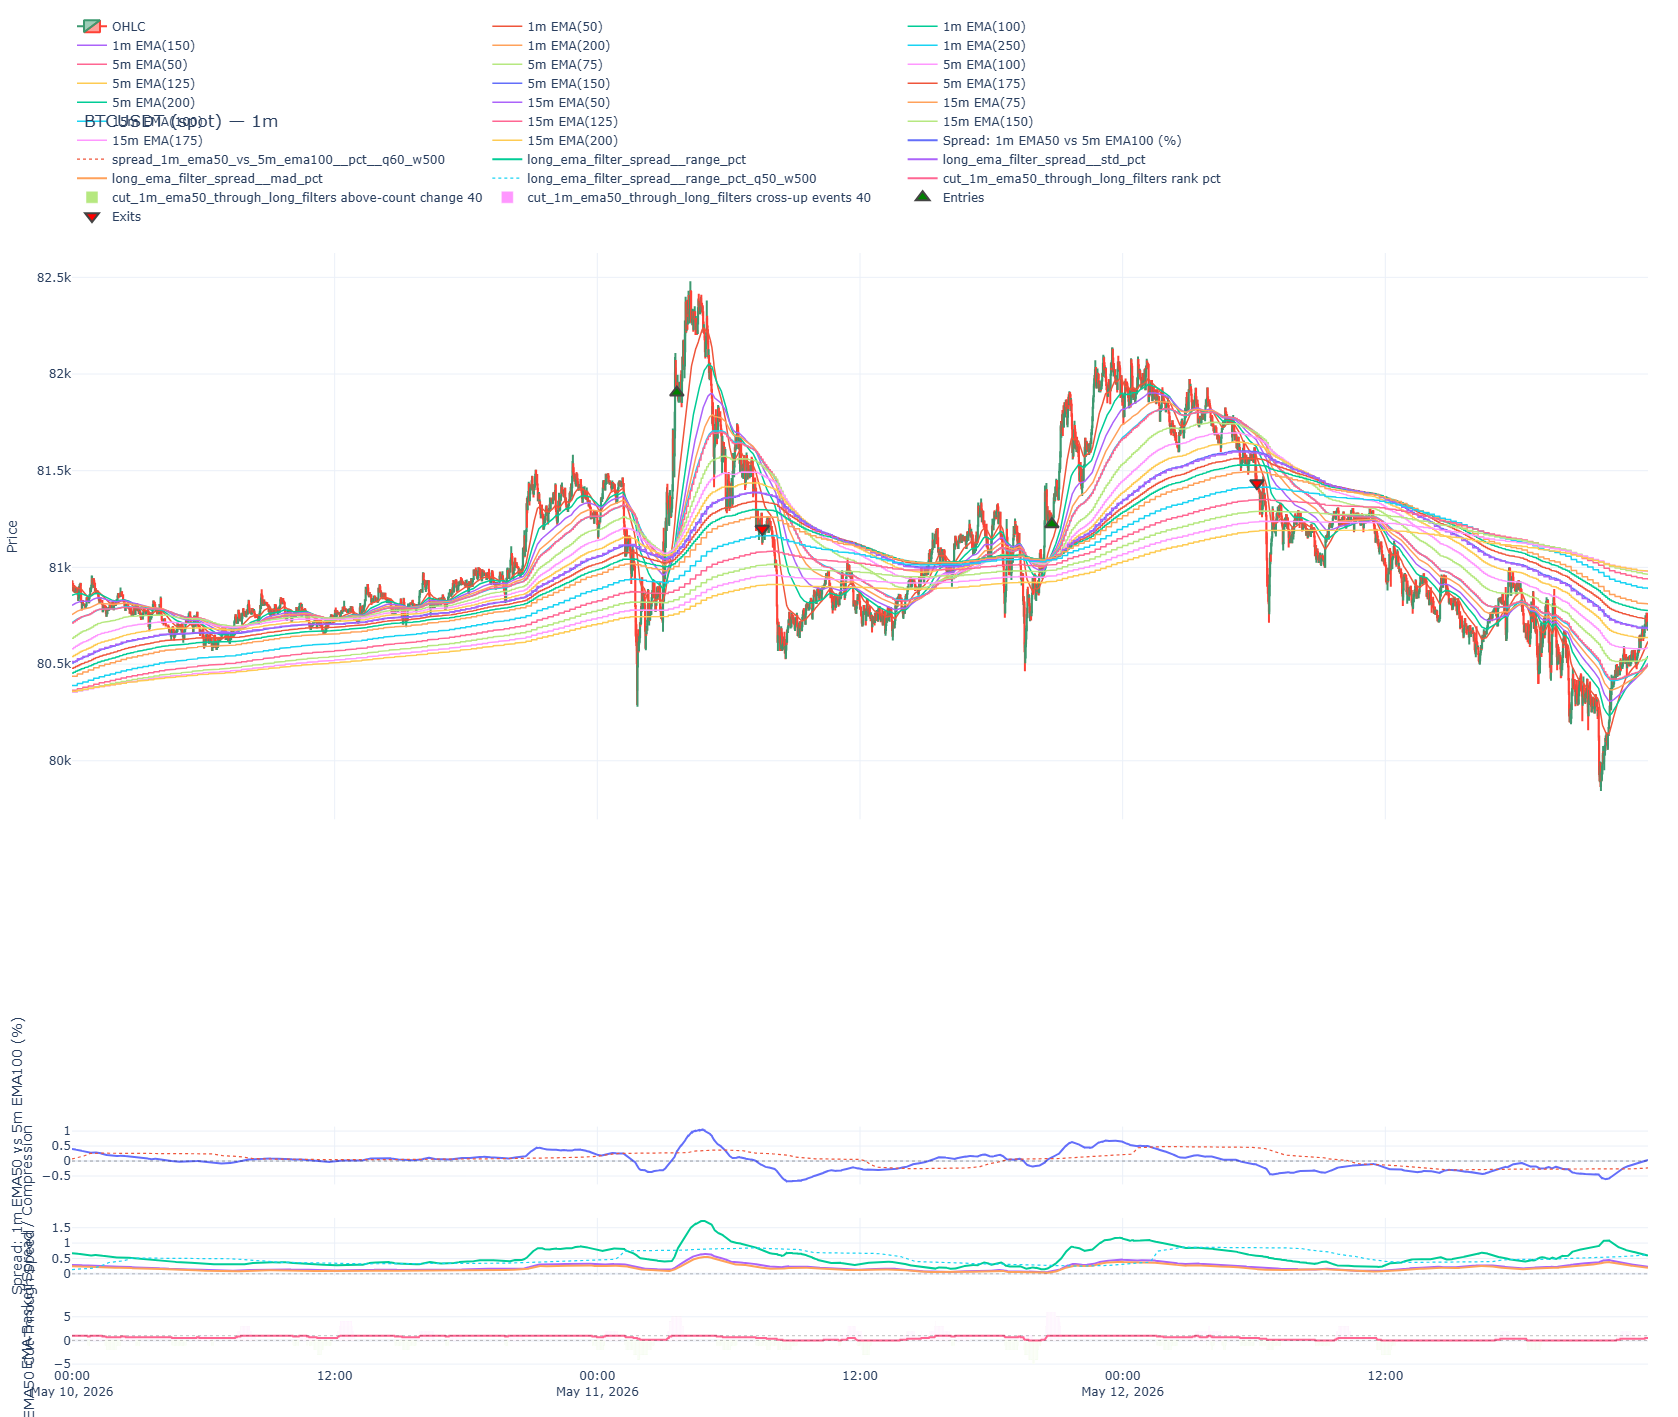

In [50]:
plot_simulation(
    df_raw=merged,
    symbol=symbol,
    interval="1m",
    market=market,
    trades=res.trades,
    ma_windows=[],
    indicators=plot_indicators,
    plot_cfg=PlotConfig(
        tz=tz,
        # date_from="2026-05-06",
        # date_to="2026-05-10",
        date_from="2026-5-10",
        date_to="2026-5-13",
        height=1400,
        width=1900,
    ),
)

# plot_simulation(
#     df_raw=df1_feat,  # (ideally raw candles df; but if yours works as-is, ok)
#     symbol=symbol,
#     interval="5m",
#     market=market,
#     trades=res.trades,
#     ma_windows=[20],
#     indicators=ind_5m,
#     plot_cfg=PlotConfig(
#         tz="Asia/Karachi",
#         date_from="2026-02-01",
#         date_to="2026-02-05",
#         height=1400,
#         width=1900
#     ),
# )